In [1]:
from qiskit import QuantumCircuit
# Build a quantum circuit
circuit = QuantumCircuit(3, 3)
circuit.x(1)
circuit.h(range(3))
circuit.cx(0, 1)
circuit.measure(range(3), range(3));

In [2]:
print(circuit)

     ┌───┐          ┌─┐   
q_0: ┤ H ├───────■──┤M├───
     ├───┤┌───┐┌─┴─┐└╥┘┌─┐
q_1: ┤ X ├┤ H ├┤ X ├─╫─┤M├
     ├───┤└┬─┬┘└───┘ ║ └╥┘
q_2: ┤ H ├─┤M├───────╫──╫─
     └───┘ └╥┘       ║  ║ 
c: 3/═══════╩════════╩══╩═
            2        0  1 


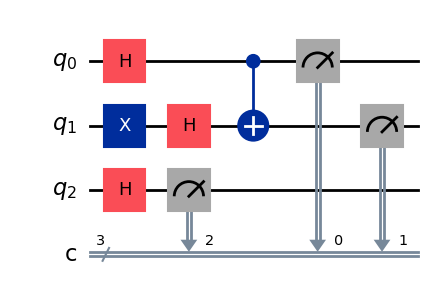

In [3]:
# Matplotlib drawing
circuit.draw(output="mpl")

In [4]:
from qiskit import QuantumRegister, ClassicalRegister

# Draw a new circuit with barriers and more registers
q_a = QuantumRegister(3, name="a")
q_b = QuantumRegister(5, name="b")
c_a = ClassicalRegister(3)
c_b = ClassicalRegister(5)

circuit = QuantumCircuit(q_a, q_b, c_a, c_b)
circuit.x(q_a[1])
circuit.x(q_b[1])
circuit.x(q_b[2])
circuit.x(q_b[4])
circuit.barrier()
circuit.h(q_a)
circuit.barrier(q_a)
circuit.h(q_b)
circuit.cswap(q_b[0], q_b[1], q_b[2])
circuit.cswap(q_b[2], q_b[3], q_b[4])
circuit.cswap(q_b[3], q_b[4], q_b[0])
circuit.barrier(q_b)
circuit.measure(q_a, c_a)
circuit.measure(q_b, c_b);

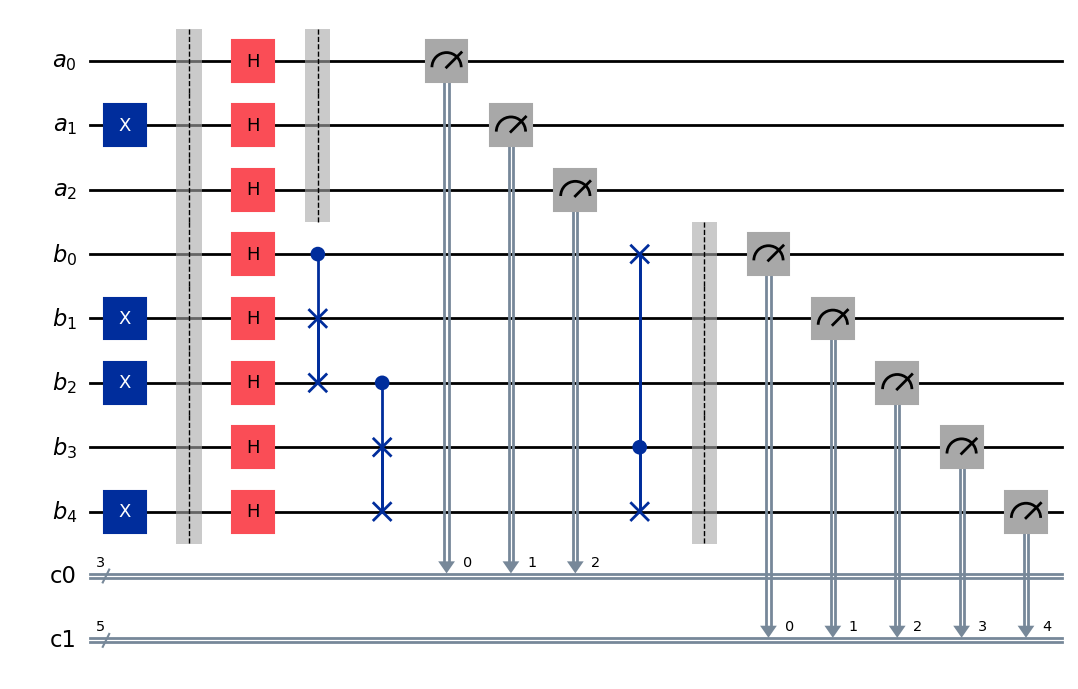

In [5]:
# Draw the circuit
circuit.draw(output="mpl")

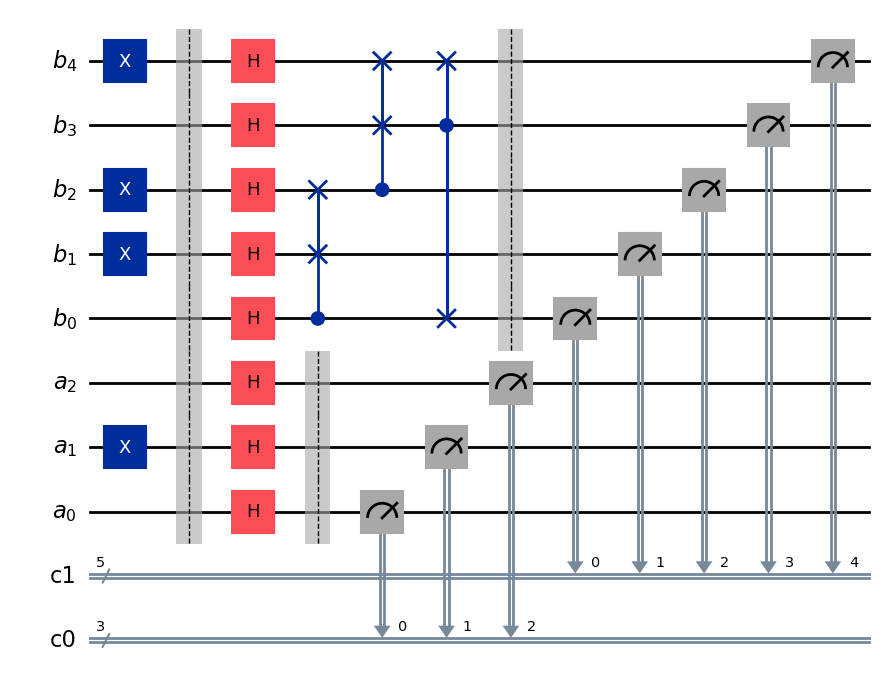

In [6]:
# Draw the circuit with reversed bit order
circuit.draw(output="mpl", reverse_bits=True)

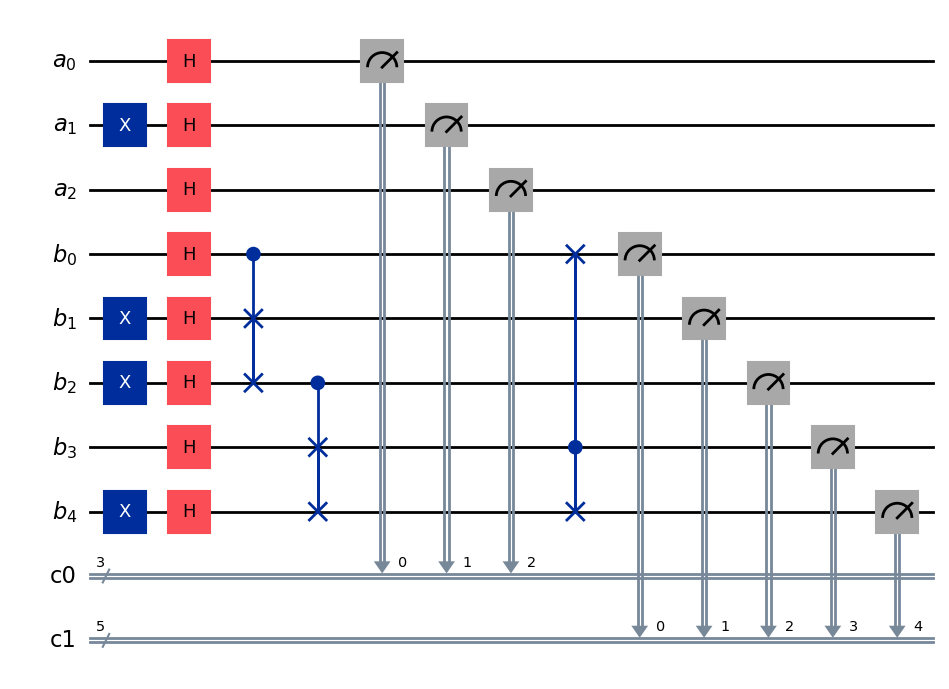

In [7]:
# Draw the circuit without barriers
circuit.draw(output="mpl", plot_barriers=False)

Visualize circuit timing


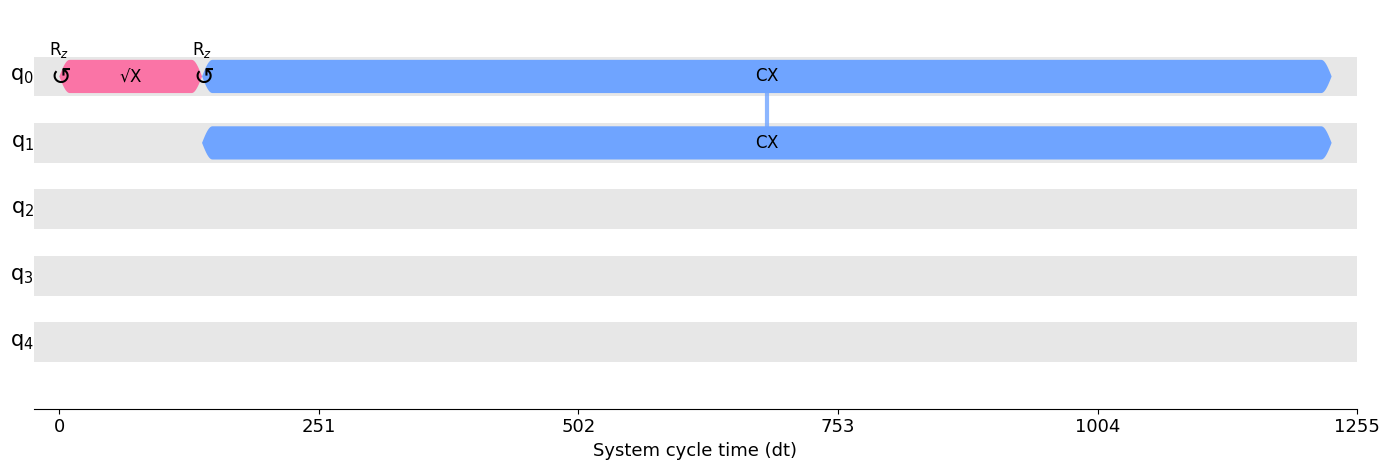

In [8]:
from qiskit import QuantumCircuit
from qiskit.visualization.timeline import draw
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.transpiler import generate_preset_pass_manager

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)

backend = GenericBackendV2(5)

pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)

draw(isa_circuit, target=backend.target)

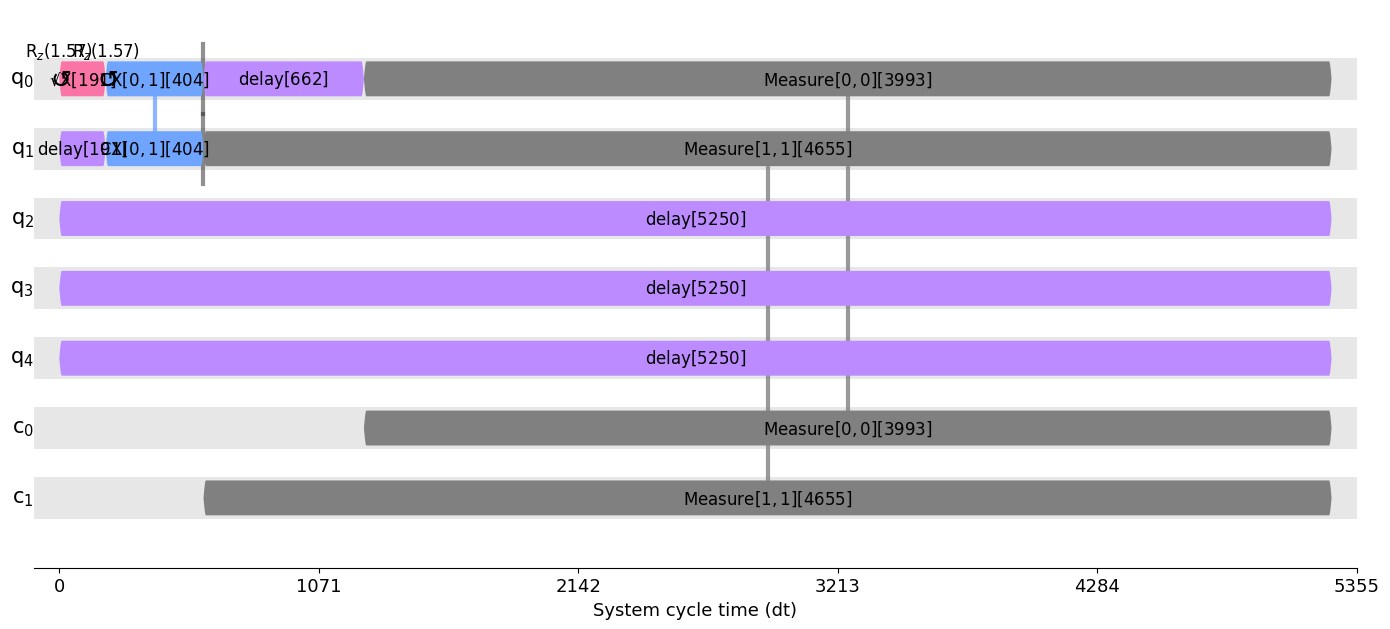

In [9]:
from qiskit import QuantumCircuit
from qiskit.visualization.timeline import draw, IQXDebugging
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.transpiler import generate_preset_pass_manager

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()

backend = GenericBackendV2(5)
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)
draw(isa_circuit, style=IQXDebugging(), target=backend.target)

Plot quantum states

In [10]:
from math import pi
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# Create a Bell state for demonstration
qc = QuantumCircuit(2)
qc.h(0)
qc.crx(pi / 2, 0, 1)
psi = Statevector(qc)

In [11]:
psi.draw("latex")  # psi is a Statevector object

<IPython.core.display.Latex object>

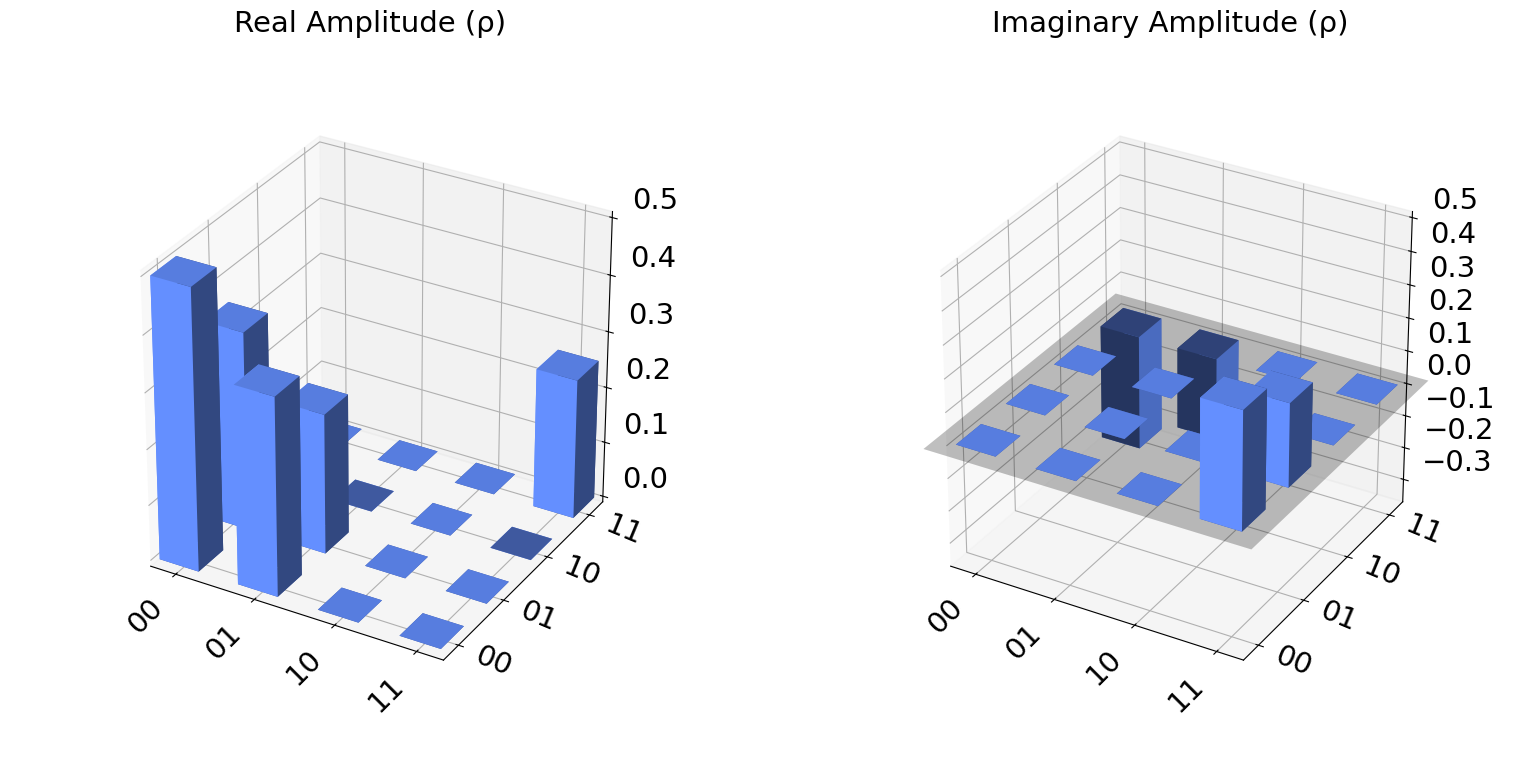

In [12]:
from qiskit.visualization import plot_state_city

plot_state_city(psi)
psi.draw("city")

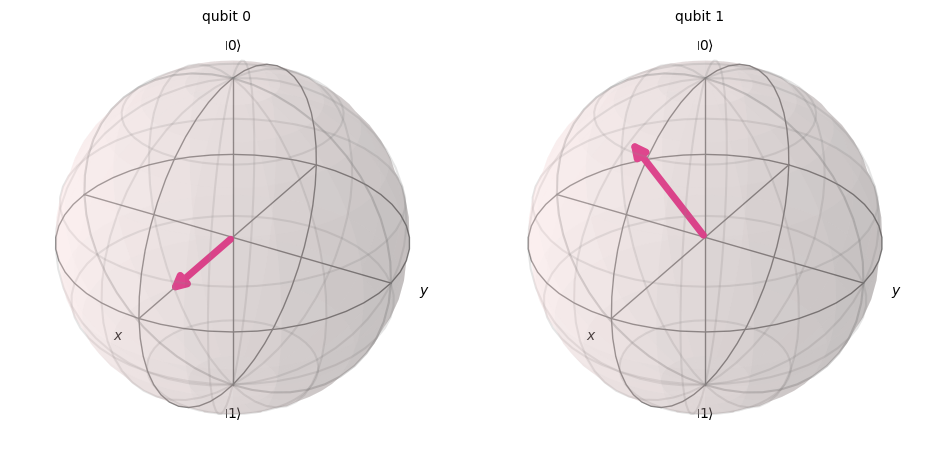

In [13]:
from qiskit.visualization import plot_bloch_multivector

plot_bloch_multivector(psi)
psi.draw("bloch")

Visualize results

In [14]:
from qiskit.primitives import StatevectorSampler as Sampler
from qiskit.transpiler import generate_preset_pass_manager

from qiskit.circuit import QuantumCircuit
from qiskit.visualization import plot_histogram

In [15]:
# Quantum circuit to make a Bell state
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
bell.measure_all()

pm = generate_preset_pass_manager(optimization_level=1)
isa_circuit = pm.run(bell)

# execute the quantum circuit
sampler = Sampler()
job = sampler.run([isa_circuit])
result = job.result()

print(result)

PrimitiveResult([SamplerPubResult(data=DataBin(meas=BitArray(<shape=(), num_shots=1024, num_bits=2>)), metadata={'shots': 1024, 'circuit_metadata': {}})], metadata={'version': 2})


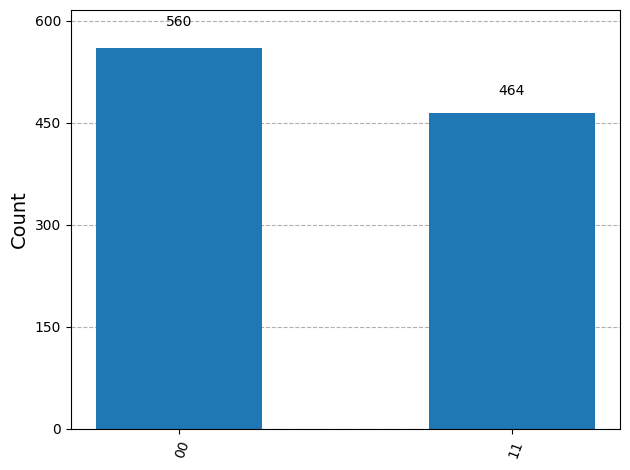

In [16]:
plot_histogram(result[0].data.meas.get_counts())

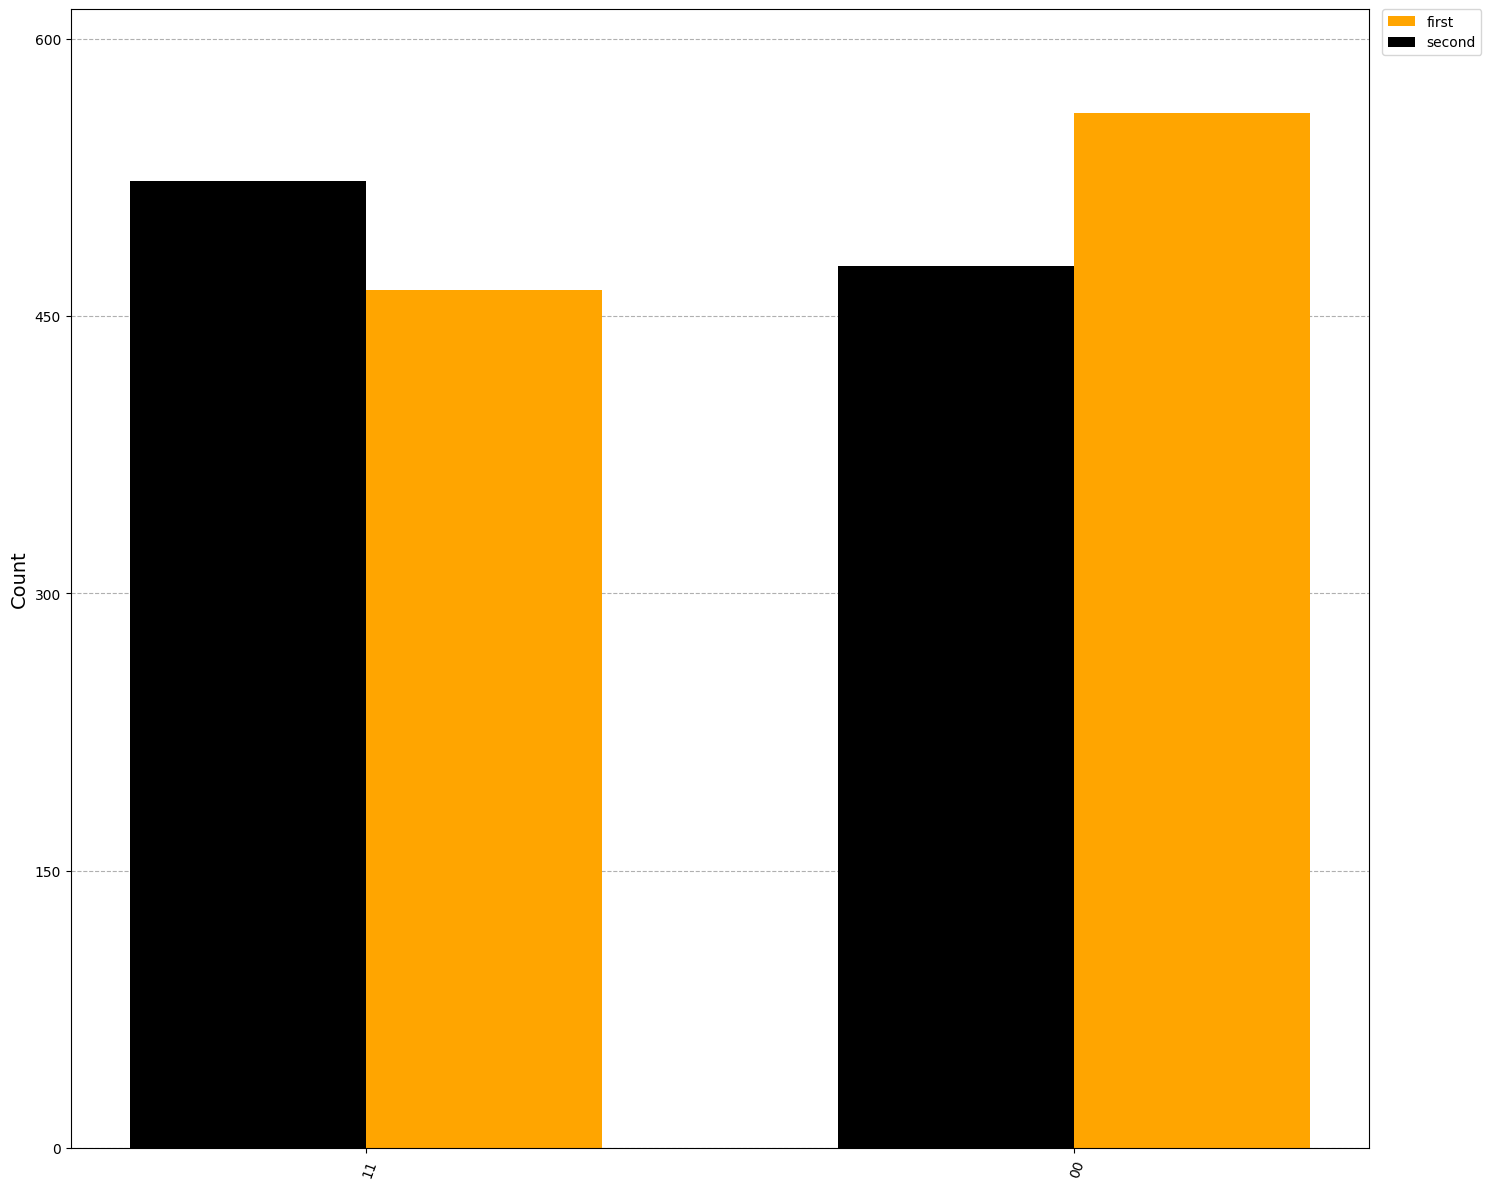

In [17]:
# Execute two-qubit Bell state again

job = sampler.run([isa_circuit], shots=1000)
second_result = job.result()

# Plot results with custom options
plot_histogram(
    [
        result[0].data.meas.get_counts(),
        second_result[0].data.meas.get_counts(),
    ],
    legend=["first", "second"],
    sort="desc",
    figsize=(15, 12),
    color=["orange", "black"],
    bar_labels=False,
)

PubResult(data=DataBin(evs=np.ndarray(<shape=(7, 1), dtype=float64>), stds=np.ndarray(<shape=(7, 1), dtype=float64>), shape=(7, 1)), metadata={'target_precision': 0.0, 'circuit_metadata': {}})


<BarContainer object of 7 artists>

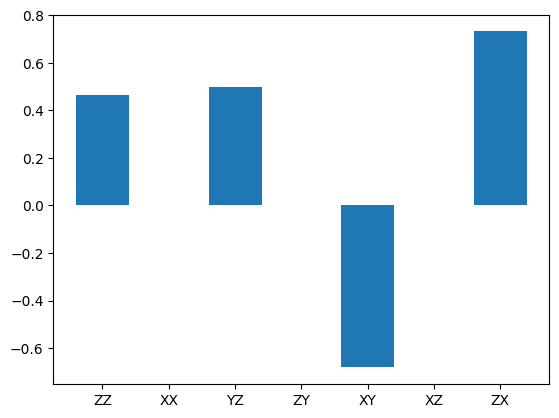

In [18]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator as Estimator
from qiskit.transpiler import generate_preset_pass_manager
from matplotlib import pyplot as plt

# Simple estimation experiment to create results
qc = QuantumCircuit(2)
qc.h(0)
qc.crx(1.5, 0, 1)

observables_labels = ["ZZ", "XX", "YZ", "ZY", "XY", "XZ", "ZX"]
observables = [SparsePauliOp(label) for label in observables_labels]

pm = generate_preset_pass_manager(optimization_level=1)
isa_circuit = pm.run(qc)
isa_observables = [
    operator.apply_layout(isa_circuit.layout) for operator in observables
]

# Reshape observable array for broadcasting
reshaped_ops = np.fromiter(isa_observables, dtype=object)
reshaped_ops = reshaped_ops.reshape((7, 1))

estimator = Estimator()
job = estimator.run([(isa_circuit, reshaped_ops)])
result = job.result()[0]
exp_val = job.result()[0].data.evs
print(result)

# Since the result array is structured as a 2D array where each element is a
# list containing a single value, you need to flatten the array.

# Plot using Matplotlib
plt.bar(observables_labels, exp_val.flatten())

Text(0.5, 1.0, 'Expectation values (with standard errors)')

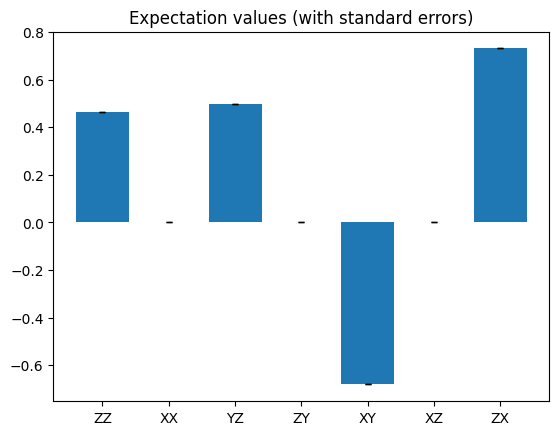

In [19]:
standard_error = job.result()[0].data.stds

_, ax = plt.subplots()
ax.bar(
    observables_labels,
    exp_val.flatten(),
    yerr=standard_error.flatten(),
    capsize=2,
)
ax.set_title("Expectation values (with standard errors)")